In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from io import StringIO
import plotly.express as px
from google.colab import files
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import learning_curve
from sklearn.metrics import accuracy_score, confusion_matrix , classification_report
from sklearn.pipeline import make_pipeline

In [3]:
uploaded = files.upload()

Saving Student_performance_data.csv to Student_performance_data.csv


In [4]:
df = pd.read_csv("Student_performance_data.csv")
df.head(10)

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,1001,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196,2.0
1,1002,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915,1.0
2,1003,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602,4.0
3,1004,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218,3.0
4,1005,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061,4.0
5,1006,18,0,0,1,8.191219,0,0,1,1,0,0,0,3.084184,1.0
6,1007,15,0,1,1,15.601680,10,0,3,0,1,0,0,2.748237,2.0
7,1008,15,1,1,4,15.424496,22,1,1,1,0,0,0,1.360143,4.0
8,1009,17,0,0,0,4.562008,1,0,2,0,1,0,1,2.896819,2.0
9,1010,16,1,0,1,18.444466,0,0,3,1,0,0,0,3.573474,0.0


In [5]:
df.drop( "StudentID", axis=1,inplace = True)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2392 entries, 0 to 2391
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Age                2392 non-null   int64  
 1   Gender             2392 non-null   int64  
 2   Ethnicity          2392 non-null   int64  
 3   ParentalEducation  2392 non-null   int64  
 4   StudyTimeWeekly    2392 non-null   float64
 5   Absences           2392 non-null   int64  
 6   Tutoring           2392 non-null   int64  
 7   ParentalSupport    2392 non-null   int64  
 8   Extracurricular    2392 non-null   int64  
 9   Sports             2392 non-null   int64  
 10  Music              2392 non-null   int64  
 11  Volunteering       2392 non-null   int64  
 12  GPA                2392 non-null   float64
 13  GradeClass         2392 non-null   float64
dtypes: float64(3), int64(11)
memory usage: 261.8 KB


In [6]:
df.isnull().sum()

,0
Age,0
Gender,0
Ethnicity,0
ParentalEducation,0
StudyTimeWeekly,0
Absences,0
Tutoring,0
ParentalSupport,0
Extracurricular,0
Sports,0


In [7]:
df.duplicated().sum()

np.int64(0)

In [ ]:
fig_Age = px.box(df , x = 'Age')
fig_Gender = px.box(df , x = 'Gender')
fig_Ethnicity = px.box(df , x = 'Ethnicity')
fig_ParentalEducation = px.box(df , x = 'ParentalEducation')
fig_StudyTimeWeekly = px.box(df , x = 'StudyTimeWeekly')
fig_Absences = px.box(df , x = 'Absences')
fig_Tutoring = px.box(df , x = 'Tutoring')
fig_ParentalSupport = px.box(df , x = 'ParentalSupport')
fig_Extracurricular = px.box(df , x = 'Extracurricular')
fig_Sports = px.box(df , x = 'Sports')
fig_Music = px.box(df , x = 'Music')
fig_Volunteering = px.box(df , x = 'Volunteering')
fig_GPA = px.box(df , x = 'GPA')

fig_Age.show()
fig_Gender.show()
fig_Ethnicity.show()
fig_ParentalEducation.show()
fig_StudyTimeWeekly.show()
fig_Absences.show()
fig_Tutoring.show()
fig_ParentalSupport.show()
fig_Extracurricular.show()
fig_Sports.show()
fig_Music.show()
fig_Volunteering.show()
fig_GPA.show()

In [8]:
q1_ParentalEduc = df['ParentalEducation'].quantile(0.25)
q3_ParentalEduc = df['ParentalEducation'].quantile(0.75)
iqr_ParentalEduc = q3_ParentalEduc - q1_ParentalEduc
q1_ParentalEduc , q3_ParentalEduc , iqr_ParentalEduc
upper_ParentalEduc = q3_ParentalEduc + (1.5 * iqr_ParentalEduc)
lower_ParentalEduc = q1_ParentalEduc - (1.5 * iqr_ParentalEduc)
upper_ParentalEduc , lower_ParentalEduc

(np.float64(3.5), np.float64(-0.5))

In [13]:
outliers_ParentalEduc = df.loc[(df['ParentalEducation'] > upper_ParentalEduc) | (df['ParentalEducation'] < lower_ParentalEduc)]
print(outliers_ParentalEduc['ParentalEducation'],'outliers = ',len(outliers_ParentalEduc['ParentalEducation']))

7       4
23      4
56      4
57      4
66      4
       ..
2178    4
2238    4
2243    4
2318    4
2368    4
Name: ParentalEducation, Length: 120, dtype: int64 outliers =  120


In [ ]:
new_df =  df.loc[(df['ParentalEducation'] < upper_ParentalEduc) & (df['ParentalEducation'] > lower_ParentalEduc)]
print('before removing outliers:' , len(df))
print('after removing outliers:' , len(new_df))
print('outliers:' , len(df) - len(new_df))

before removing outliers: 2392
after removing outliers: 2272
outliers: 120


In [ ]:
X = new_df.drop("GradeClass",axis=1)
y = new_df["GradeClass"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [ ]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)  # fit on train only
X_test_scaled = scaler.transform(X_test)

In [ ]:
log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X_train_scaled, y_train)

LogisticRegression(max_iter=1000)

In [ ]:
tree = DecisionTreeClassifier(random_state=42)
tree.fit(X_train, y_train)

DecisionTreeClassifier(random_state=42)

In [ ]:
forest = RandomForestClassifier(n_estimators=200,max_features='sqrt', random_state=42)
forest.fit(X_train, y_train)

RandomForestClassifier(n_estimators=200, random_state=42)

In [ ]:
test_acc_log = accuracy_score(y_test, log_reg.predict(X_test_scaled))
test_acc_tree = accuracy_score(y_test, tree.predict(X_test))
test_acc_forest = accuracy_score(y_test, forest.predict(X_test))

print("Logistic Regression Accuracy:", test_acc_log)
print("Decision Tree Accuracy:", test_acc_tree)
print("Random Forest Accuracy:", test_acc_forest)

Logistic Regression Accuracy: 0.7450549450549451
Decision Tree Accuracy: 0.8373626373626374
Random Forest Accuracy: 0.9010989010989011


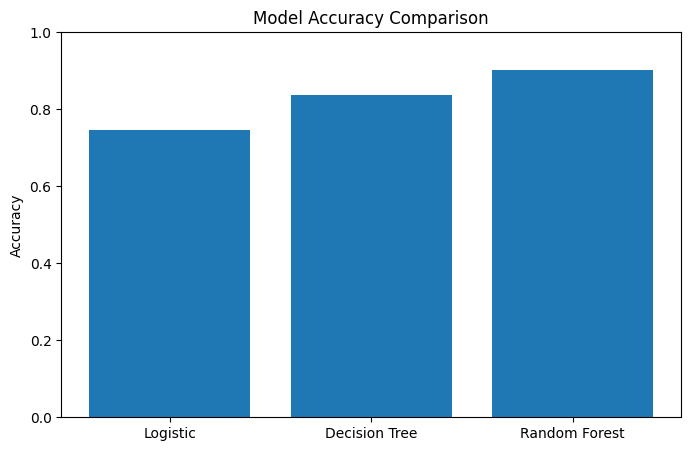

In [ ]:
plt.figure(figsize=(8,5))
plt.bar(["Logistic", "Decision Tree", "Random Forest"],
        [test_acc_log, test_acc_tree, test_acc_forest])
plt.title("Model Accuracy Comparison")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.show()

In [ ]:
def get_accuracies(model, X_train, y_train, X_test, y_test):
    model.fit(X_train, y_train)

    train_acc = accuracy_score(y_train, model.predict(X_train))
    test_acc = accuracy_score(y_test, model.predict(X_test))

    return train_acc, test_acc

In [ ]:
log_train, log_test = get_accuracies(
    log_reg,
    X_train_scaled, y_train,
    X_test_scaled, y_test
)
tree_train, tree_test = get_accuracies(
    tree,
    X_train, y_train,
    X_test, y_test
)
forest_train, forest_test = get_accuracies(
    forest,
    X_train, y_train,
    X_test, y_test
)

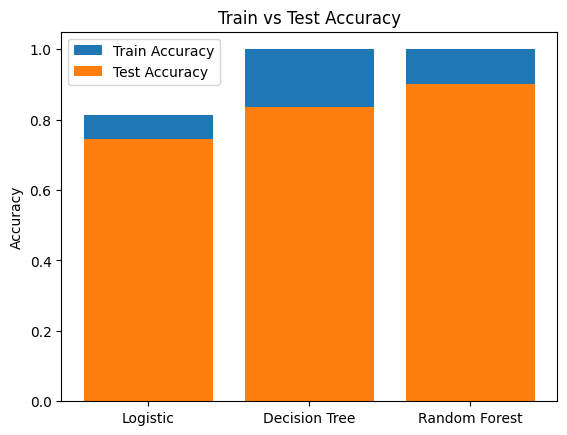

In [ ]:
models = ['Logistic', 'Decision Tree', 'Random Forest']
train_scores = [log_train, tree_train, forest_train]
test_scores = [log_test, tree_test, forest_test]

x = range(len(models))

plt.figure()
plt.bar(x, train_scores)
plt.bar(x, test_scores)

plt.xticks(x, models)
plt.ylabel('Accuracy')
plt.title('Train vs Test Accuracy')

plt.legend(['Train Accuracy', 'Test Accuracy'])
plt.show()


In [ ]:
def plot_learning_curve(model, X, y, title):
    train_sizes, train_scores, test_scores = learning_curve(
        model, X, y,
        train_sizes=np.linspace(0.1, 1.0, 5),
        cv=5
    )
    plt.figure()
    plt.plot(train_sizes, train_scores.mean(axis=1))
    plt.plot(train_sizes, test_scores.mean(axis=1))
    plt.xlabel('Training Size')
    plt.ylabel('Accuracy')
    plt.title(title)
    plt.legend(['Train', 'Validation'])
    plt.show()


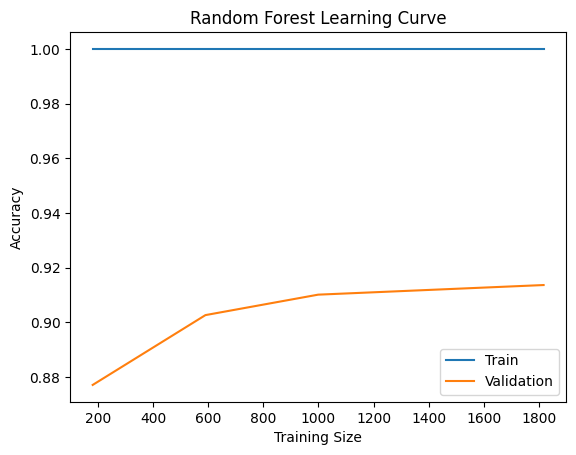

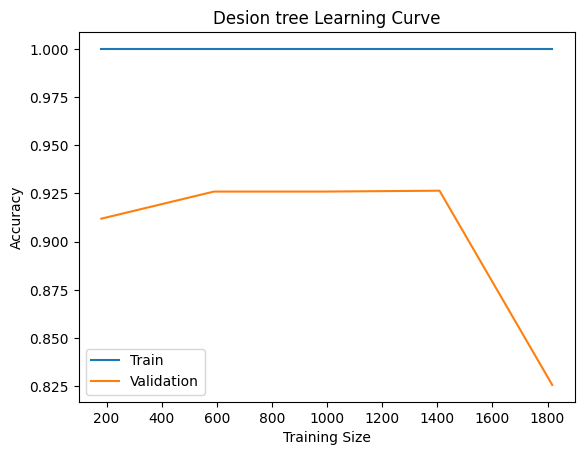

In [ ]:
plot_learning_curve(
    forest,
    X, y,
    'Random Forest Learning Curve'
)
plot_learning_curve(
    tree,
    X, y,
    'Desion tree Learning Curve'
)

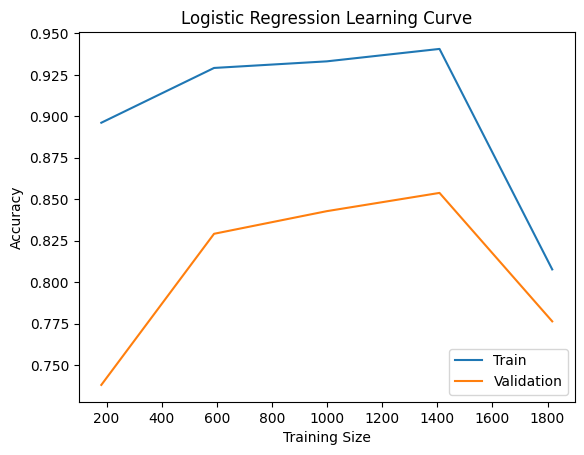

In [ ]:
pipe = make_pipeline(
    StandardScaler(),
    LogisticRegression()
)
pipe.fit(X_train, y_train)
pipe.predict(X_test)
plot_learning_curve(
    pipe,
    X, y,
    'Logistic Regression Learning Curve'
)

In [ ]:
models = [
    ("Logistic Regression", pipe, X_train, X_test),
    ("Decision Tree", tree, X_train, X_test),
    ("Random Forest", forest, X_train, X_test)
]

# حساب التقارير لكل نموذج
for name, model, X_tr, X_te in models:
    model.fit(X_tr, y_train)
    y_pred = model.predict(X_te)
    print(f"\n=== {name} ===")
    print(classification_report(y_test, y_pred, digits=3))


=== Logistic Regression ===
              precision    recall  f1-score   support

         0.0      0.000     0.000     0.000        22
         1.0      0.508     0.652     0.571        46
         2.0      0.524     0.573     0.548        75
         3.0      0.803     0.538     0.645        91
         4.0      0.871     0.982     0.923       221

    accuracy                          0.745       455
   macro avg      0.542     0.549     0.537       455
weighted avg      0.722     0.745     0.726       455


=== Decision Tree ===
              precision    recall  f1-score   support

         0.0      0.448     0.591     0.510        22
         1.0      0.766     0.783     0.774        46
         2.0      0.806     0.773     0.789        75
         3.0      0.908     0.758     0.826        91
         4.0      0.887     0.928     0.907       221

    accuracy                          0.837       455
   macro avg      0.763     0.767     0.761       455
weighted avg      0.845  

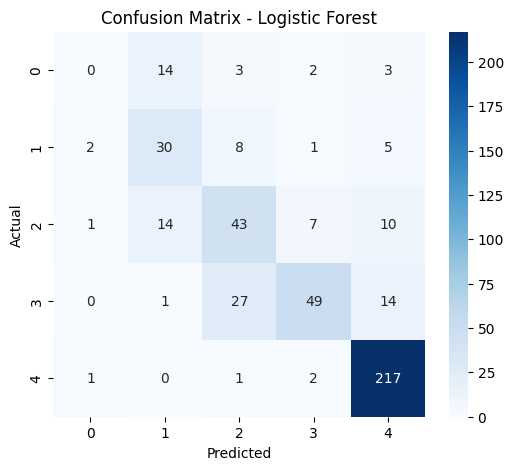

In [ ]:
cm = confusion_matrix(y_test, pipe.predict(X_test))

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix - Logistic Forest")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

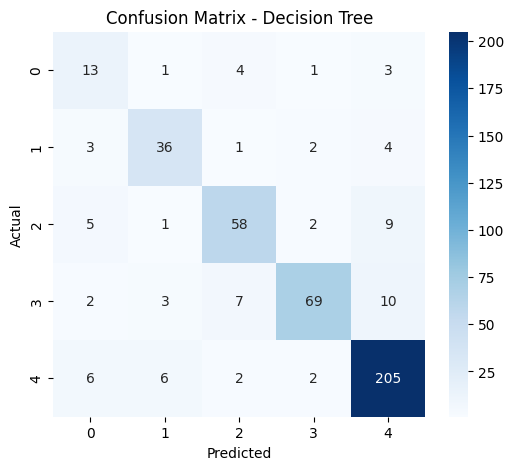

In [ ]:
cm = confusion_matrix(y_test, tree.predict(X_test))

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix - Decision Tree")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

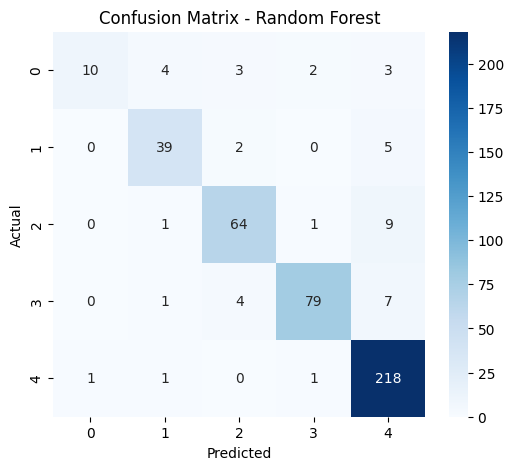

In [ ]:
cm = confusion_matrix(y_test, forest.predict(X_test))

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix - Random Forest")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

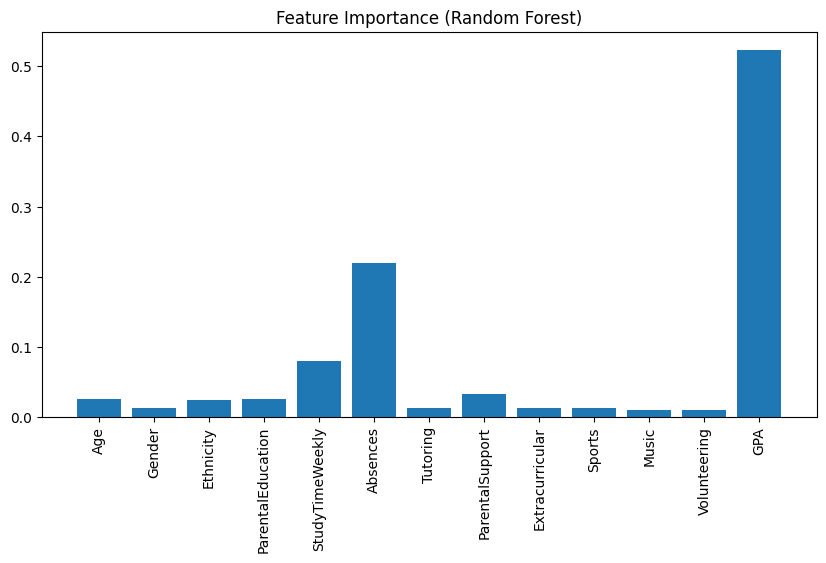

In [ ]:
importances = forest.feature_importances_
features = X.columns
plt.figure(figsize=(10,5))
plt.bar(features, importances)
plt.xticks(rotation=90)
plt.title("Feature Importance (Random Forest)")
plt.show()